In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/baseline.pt
/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/part_A.pt
/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/part_B.pt


In [5]:
!pip install -q ultralytics
from pathlib import Path

for w in sorted(Path("/kaggle/input").rglob("*.pt")):
    print(w)

/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/baseline.pt
/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/part_A.pt
/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/part_B.pt


In [6]:
from ultralytics.data.utils import check_det_dataset
data = check_det_dataset("VisDrone.yaml")
names = data["names"]
print("train:", data["train"])
print("val:  ", data["val"])
print("test: ", data["test"])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/kaggle/working/datasets/VisDrone/images/val'
Unzipping /kaggle/working/datasets/VisDrone/VisDrone2019-DET-val.zip to /kaggle/working/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 735.1files/s 1.5s0.1s4s<10.5s<0.2s
Unzipping /kaggle/working/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /kaggle/working/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 1.4Kfiles/s 2.3s7s1ss
Unzipping /kaggle/working/datasets/VisDrone/VisDrone2019-DET-train.zip to /kaggle/working/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 2.1Kfiles/s 6.3s<0.0s
Converting train: ━━━━

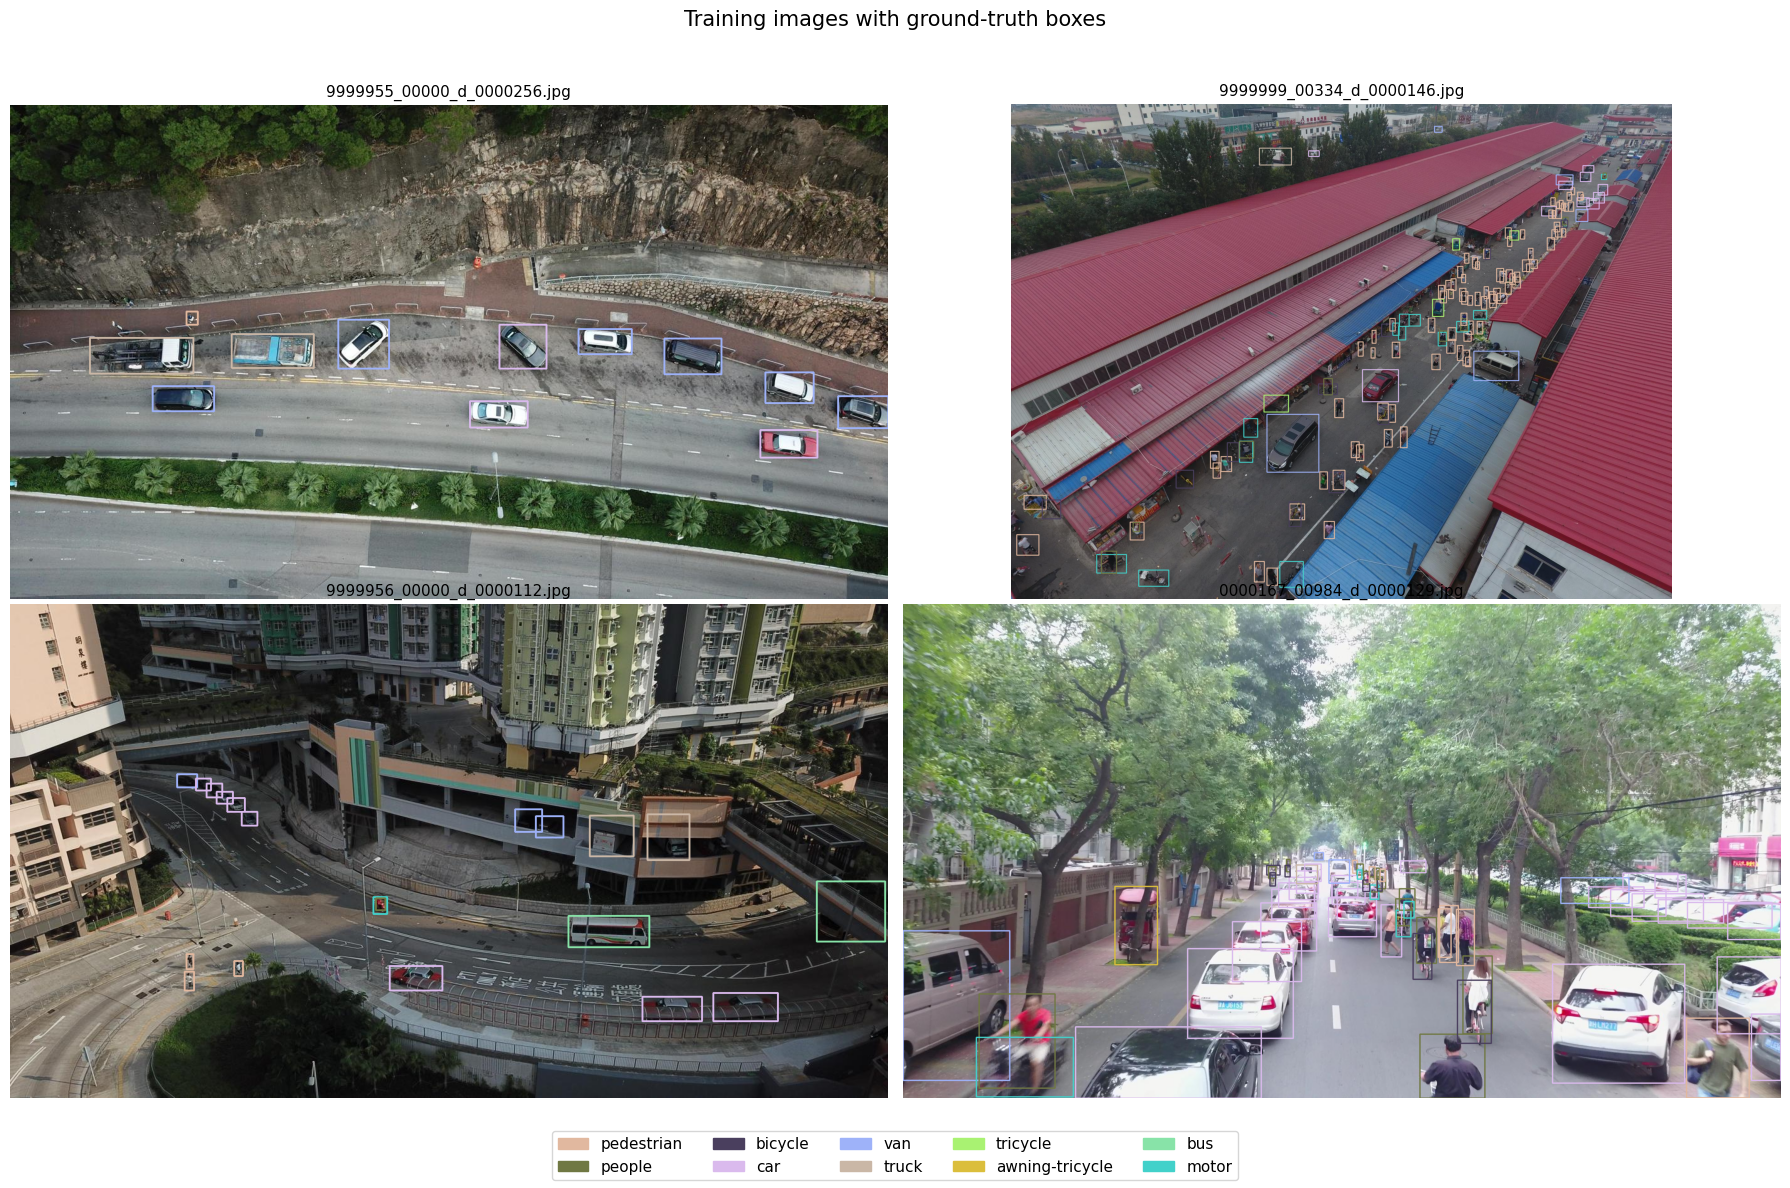

In [7]:
import cv2, random, numpy as np, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ultralytics.data.utils import img2label_paths

rng = np.random.default_rng(0)
COLORS = {i: tuple(int(v) for v in rng.integers(60, 255, 3)) for i in names}

def draw_ground_truth(img_path):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = Path(img2label_paths([str(img_path)])[0])
    if lbl.exists():
        for c, xc, yc, bw, bh in np.loadtxt(lbl, ndmin=2):
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[int(c)], 2)
    return img

def show_grid(images, titles, suptitle, cols=2):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(9 * cols, 6 * rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, img, t in zip(np.ravel(axes), images, titles):
        ax.imshow(img)
        ax.set_title(t, fontsize=11)
    handles = [mpatches.Patch(color=np.array(COLORS[i]) / 255, label=n) for i, n in names.items()]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=11)
    fig.suptitle(suptitle, fontsize=15)
    plt.tight_layout(rect=(0, 0.06, 1, 0.96))
    plt.show()

random.seed(0)
train_imgs = sorted(Path(data["train"]).glob("*.jpg"))
picked = random.sample(train_imgs, 4)
show_grid([draw_ground_truth(p) for p in picked],
          [p.name for p in picked],
          "Training images with ground-truth boxes")

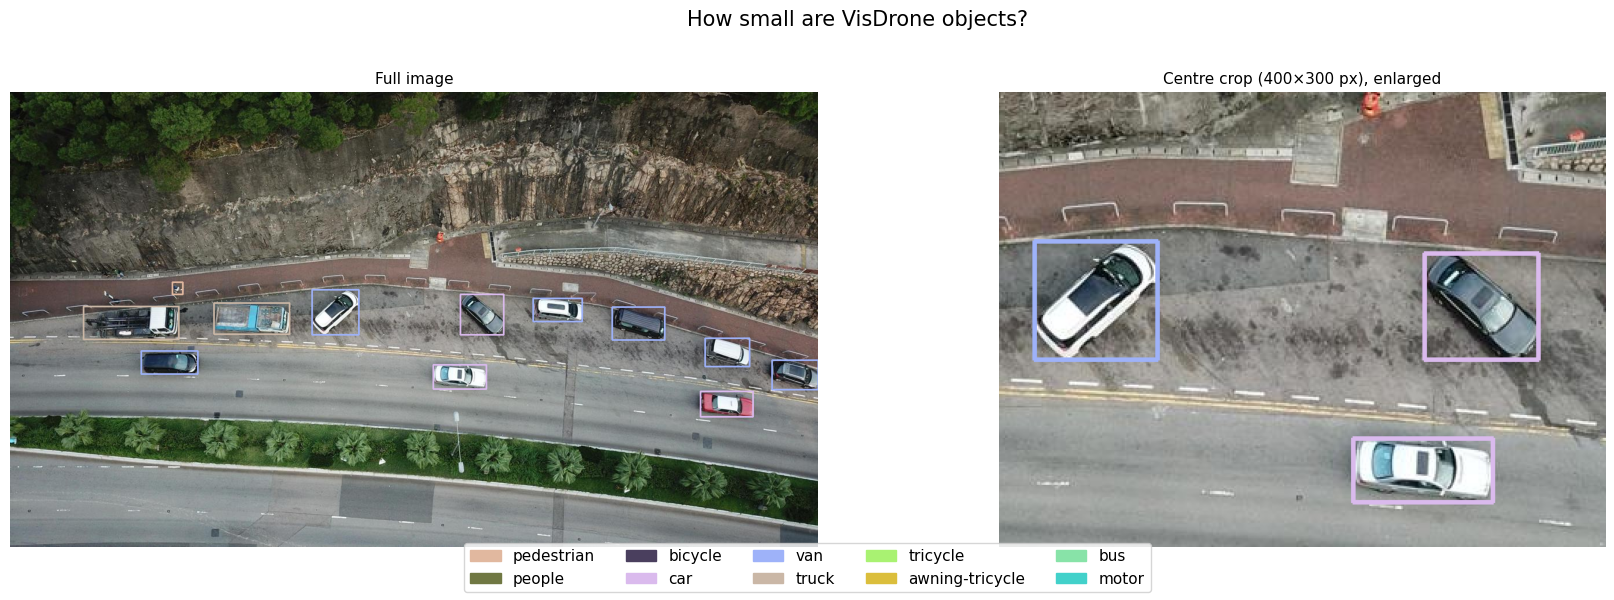

In [8]:
img = draw_ground_truth(picked[0])
h, w = img.shape[:2]
crop = img[h//2 - 150 : h//2 + 150, w//2 - 200 : w//2 + 200]

show_grid([img, crop], ["Full image", "Centre crop (400×300 px), enlarged"],
          "How small are VisDrone objects?")

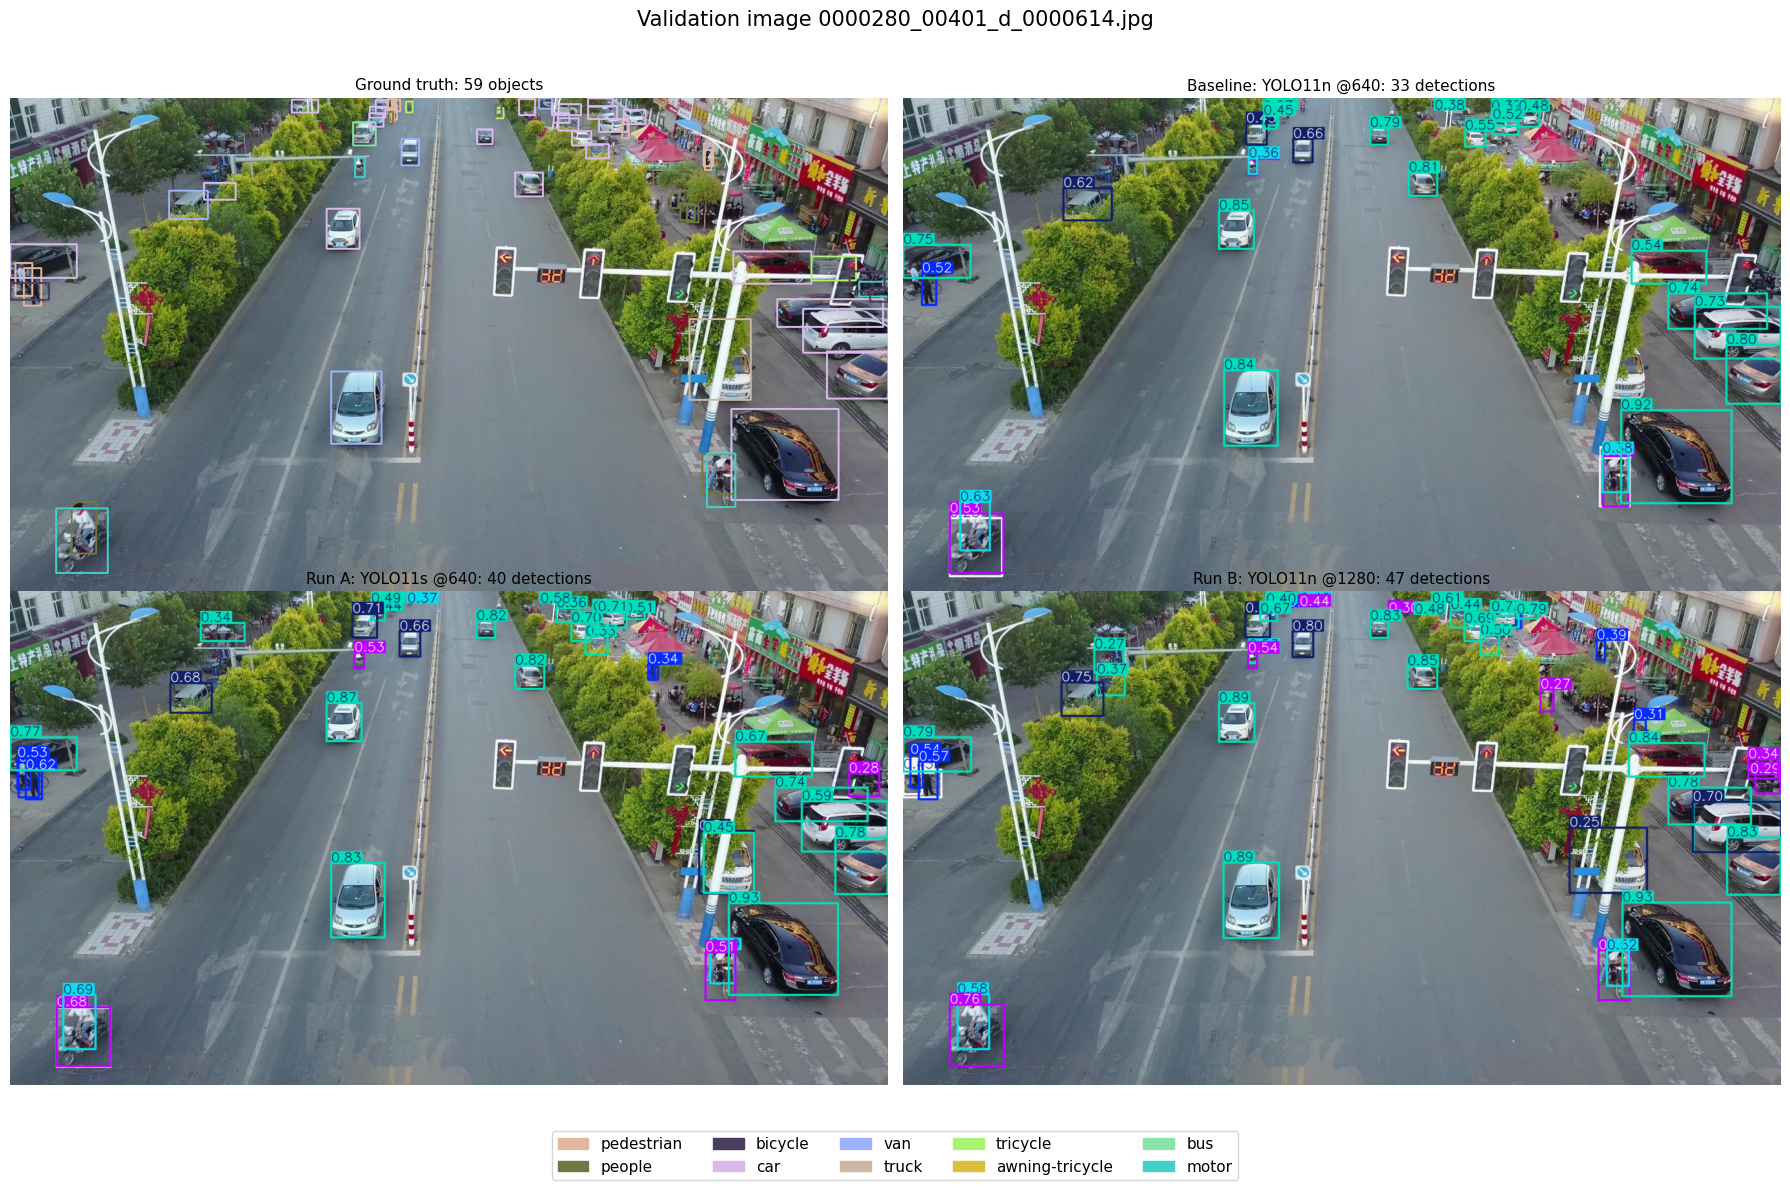

In [9]:
from ultralytics import YOLO

MODELS = {
    "Baseline: YOLO11n @640": ("/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/baseline.pt", 640),
    "Run A: YOLO11s @640":    ("/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/part_A.pt", 640),
    "Run B: YOLO11n @1280":   ("/kaggle/input/datasets/suddapallikishore/vsdrone-trained-weights/part_B.pt", 1280),
}
loaded = {name: (YOLO(path), size) for name, (path, size) in MODELS.items()}

def predict_image(model, img_path, imgsz):
    result = model.predict(str(img_path), imgsz=imgsz, conf=0.25, verbose=False)[0]
    drawn  = result.plot(labels=False, line_width=2)
    return cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB), len(result.boxes)

val_imgs = sorted(Path(data["val"]).glob("*.jpg"))
img_path = random.choice(val_imgs)

n_true = len(np.loadtxt(img2label_paths([str(img_path)])[0], ndmin=2))
images, titles = [draw_ground_truth(img_path)], [f"Ground truth: {n_true} objects"]
for name, (model, size) in loaded.items():
    drawn, n_pred = predict_image(model, img_path, size)
    images.append(drawn)
    titles.append(f"{name}: {n_pred} detections")

show_grid(images, titles, f"Validation image {img_path.name}")

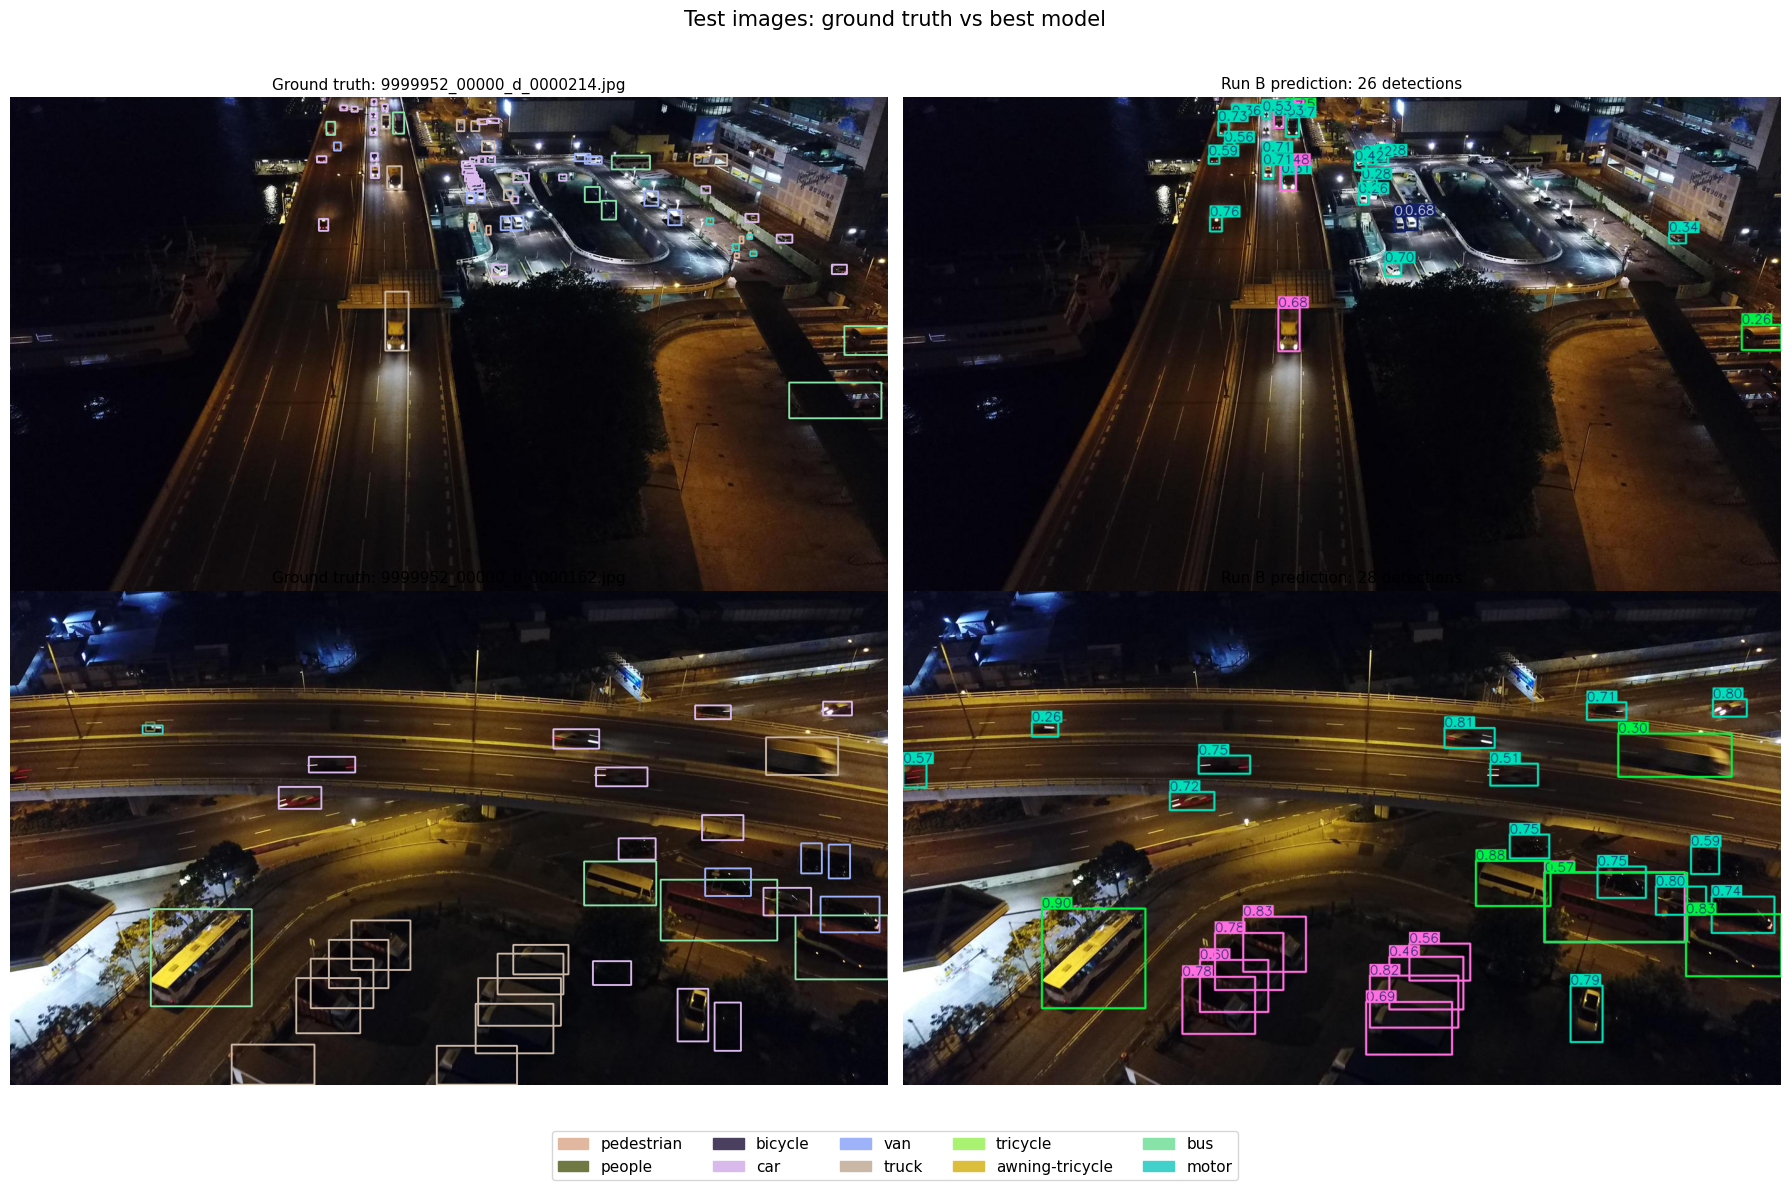

In [10]:
test_imgs = sorted(Path(data["test"]).glob("*.jpg"))
best_model, best_size = loaded["Run B: YOLO11n @1280"]

picked = random.sample(test_imgs, 2)
images, titles = [], []
for p in picked:
    images.append(draw_ground_truth(p))
    titles.append(f"Ground truth: {p.name}")
    drawn, n = predict_image(best_model, p, best_size)
    images.append(drawn)
    titles.append(f"Run B prediction: {n} detections")

show_grid(images, titles, "Test images: ground truth vs best model")

In [11]:
#Step 4b: official test scores and a fair speed benchmark
import pandas as pd

summary, per_class = [], {}

for name, (model, size) in loaded.items():
    metrics = model.val(
        data="VisDrone.yaml",
        split="test",
        imgsz=size,
        batch=8 if size == 1280 else 16,
        plots=True,
        project="/kaggle/working/test_eval",
        name=name.split(":")[0].replace(" ", "_"),
        verbose=False,
    )
    summary.append({
        "model": name,
        "precision": metrics.box.mp,
        "recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
    })
    per_class[name] = metrics.box.ap50

summary_df = pd.DataFrame(summary).round(3)
class_df = pd.DataFrame(per_class, index=[names[i] for i in range(len(names))]).round(3)
display(summary_df)
display(class_df)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2880.9±1082.1 MB/s, size: 152.3 KB)
val: Scanning /kaggle/working/datasets/VisDrone/labels/test... 1610 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1610/1610 990.8it/s 1.6s.0ss
val: New cache created: /kaggle/working/datasets/VisDrone/labels/test.cache
WARNING ⚠️ Dataset images contain up to 461 objects (test=461), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=461 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 101/101 6.4it/s 15.8s0.2s
                   all       1610      75102      0.379      0.287      0.251  

,model,precision,recall,mAP50,mAP50-95
0,Baseline: YOLO11n @640,0.379,0.287,0.251,0.137
1,Run A: YOLO11s @640,0.442,0.347,0.314,0.179
2,Run B: YOLO11n @1280,0.487,0.405,0.383,0.221


,Baseline: YOLO11n @640,Run A: YOLO11s @640,Run B: YOLO11n @1280
pedestrian,0.193,0.259,0.375
people,0.091,0.133,0.210
bicycle,0.057,0.097,0.166
car,0.648,0.710,0.782
van,0.272,0.351,0.422
truck,0.316,0.404,0.463
tricycle,0.116,0.175,0.218
awning-tricycle,0.136,0.180,0.204
bus,0.478,0.558,0.609
motor,0.201,0.279,0.382


In [12]:
import numpy as np

def benchmark(model, imgsz, images, device=0, warmup=10):
    for p in images[:warmup]:
        model.predict(str(p), imgsz=imgsz, device=device, verbose=False)

    pre, inf, post = [], [], []
    for p in images[warmup:]:
        r = model.predict(str(p), imgsz=imgsz, device=device, verbose=False)[0]
        pre.append(r.speed["preprocess"])
        inf.append(r.speed["inference"])
        post.append(r.speed["postprocess"])

    total = np.array(pre) + np.array(inf) + np.array(post)
    return {
        "inference ms (median)": np.median(inf),
        "total ms (median)": np.median(total),
        "total ms (p95)": np.percentile(total, 95),
        "FPS": 1000 / np.median(total),
    }

random.seed(1)
bench_imgs = random.sample(test_imgs, 110)

speed_rows = []
for name, (model, size) in loaded.items():
    row = {"model": name, "device": "T4 GPU"}
    row.update(benchmark(model, size, bench_imgs, device=0))
    speed_rows.append(row)

speed_df = pd.DataFrame(speed_rows).round(1)
display(speed_df)

,model,device,inference ms (median),total ms (median),total ms (p95),FPS
0,Baseline: YOLO11n @640,T4 GPU,8.4,11.2,13.1,89.4
1,Run A: YOLO11s @640,T4 GPU,8.0,10.8,13.3,92.7
2,Run B: YOLO11n @1280,T4 GPU,10.5,15.7,18.8,63.5


In [13]:
cpu_rows = []
for name, (model, size) in loaded.items():
    row = {"model": name, "device": "CPU (4 cores)"}
    row.update(benchmark(model, size, bench_imgs[:30], device="cpu", warmup=5))
    cpu_rows.append(row)

display(pd.DataFrame(cpu_rows).round(1))

,model,device,inference ms (median),total ms (median),total ms (p95),FPS
0,Baseline: YOLO11n @640,CPU (4 cores),57.4,60.6,69.9,16.5
1,Run A: YOLO11s @640,CPU (4 cores),119.6,122.9,149.0,8.1
2,Run B: YOLO11n @1280,CPU (4 cores),157.3,164.9,208.3,6.1
